AAI520 - Agentic - Assignment 7.1 Project

Amita Sirohi, Smriti Shikha, PuPurushotam , Vishakha

Sept 2026

This project builds a student-friendly Python Agentic AI Investment Research Agent that researches a stock symbol, gathers financial data, processes news, routes information to specialist analyzers, evaluates its own report, and saves notes to improve future analyses.
The implementation uses Yahoo Finance through yfinance, Python tools, and a lightweight local memory file.

It does not require a paid LLM API key

This project demonstrates the three required agentic AI workflow patterns, together with planning, dynamic tool selection, self-evaluation, and persistent memory. It can be extended with an LLM for more sophisticated reasoning, a trained financial sentiment classifier, SEC filing retrieval, or FRED economic data.

Limitations: the supplied implementation uses keyword-based news classification and extractive summaries rather than a large language model.

In [1]:
#============= begining draft

In [2]:
# Step 1: Install required libraries

%pip install -q yfinance pandas numpy matplotlib requests feedparser

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 4.1 MB/s eta 0:00:00


In [3]:
# Step 2: Import libraries

import os
import re
import json
import time
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import feedparser

from datetime import datetime, timezone
from urllib.parse import quote

warnings.filterwarnings("ignore")

# Project configuration
STOCK_SYMBOL = "AAPL"  # Change to whatever you want like MSFT, NVDA, GOOGL
PERIOD = "1y"
INTERVAL = "1d"

MEMORY_FILE = "investment_agent_memory.json"
NEWS_LIMIT = 15

print("Investment Research Agent initialized.")
print("Stock symbol:", STOCK_SYMBOL)
print("Analysis period:", PERIOD)

Investment Research Agent initialized.
Stock symbol: AAPL
Analysis period: 1y


In [4]:
# Step 3: Collect stock market data

def get_market_data(symbol, period="1y", interval="1d"):
    """
    Retrieve stock prices, company information,
    and available financial statements.
    """

    ticker = yf.Ticker(symbol)

    # Historical prices
    history = ticker.history(
        period=period,
        interval=interval,
        auto_adjust=True
    )

    if history.empty:
        raise ValueError(
            f"No price data found for {symbol}. "
            "Check the ticker symbol and internet connection."
        )

    # Company information
    try:
        info = ticker.info
        if not isinstance(info, dict):
            info = {}
    except Exception as error:
        print("Company information unavailable:", error)
        info = {}

    # Financial statements
    try:
        financials = ticker.financials
    except Exception:
        financials = pd.DataFrame()

    try:
        balance_sheet = ticker.balance_sheet
    except Exception:
        balance_sheet = pd.DataFrame()

    try:
        cash_flow = ticker.cashflow
    except Exception:
        cash_flow = pd.DataFrame()

    return {
        "symbol": symbol.upper(),
        "history": history,
        "info": info,
        "financials": financials,
        "balance_sheet": balance_sheet,
        "cash_flow": cash_flow
    }


# Collect data
market_data = get_market_data(STOCK_SYMBOL, PERIOD, INTERVAL)

print("Company:", market_data["info"].get("longName", STOCK_SYMBOL))
print("Price observations:", len(market_data["history"]))
print("Latest closing price:",
      round(market_data["history"]["Close"].iloc[-1], 2))
print("Data collection completed.")

Company: Apple Inc.
Price observations: 251
Latest closing price: 336.64
Data collection completed.


In [5]:
# Step 4: Calculate market indicators

def analyze_market(history):
    close = history["Close"].dropna()

    daily_returns = close.pct_change().dropna()

    latest_price = float(close.iloc[-1])
    first_price = float(close.iloc[0])

    total_return = (latest_price / first_price - 1) * 100

    annualized_volatility = (
        daily_returns.std() * np.sqrt(252) * 100
        if len(daily_returns) > 1 else np.nan
    )

    moving_average_20 = close.rolling(20).mean()
    moving_average_50 = close.rolling(50).mean()

    rolling_peak = close.cummax()
    drawdown = (close / rolling_peak - 1) * 100

    results = {
        "latest_price": latest_price,
        "first_price": first_price,
        "total_return_pct": total_return,
        "annualized_volatility_pct": annualized_volatility,
        "moving_average_20": (
            float(moving_average_20.iloc[-1])
            if pd.notna(moving_average_20.iloc[-1]) else np.nan
        ),
        "moving_average_50": (
            float(moving_average_50.iloc[-1])
            if pd.notna(moving_average_50.iloc[-1]) else np.nan
        ),
        "maximum_drawdown_pct": float(drawdown.min()),
        "daily_returns": daily_returns
    }

    return results


market_metrics = analyze_market(market_data["history"])

for key, value in market_metrics.items():
    if key != "daily_returns":
        print(f"{key}: {value}")

latest_price: 336.6400146484375
first_price: 244.3673095703125
total_return_pct: 37.75983998857062
annualized_volatility_pct: 24.466993637158616
moving_average_20: 335.38900299072264
moving_average_50: 322.3565734863281
maximum_drawdown_pct: -13.798523953754415


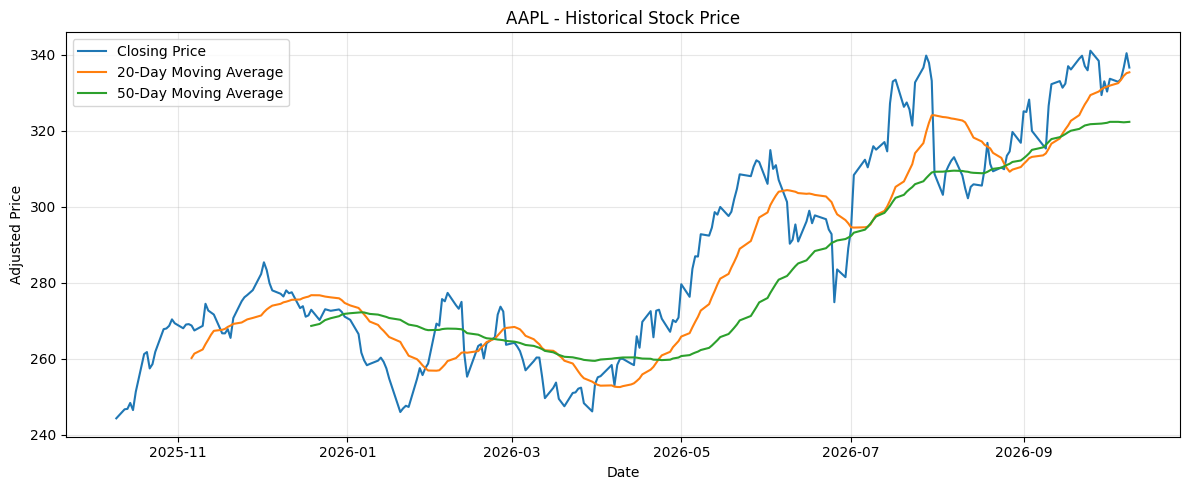

Market exploration completed.


In [6]:
# Step 5: Plot stock price and moving averages

history = market_data["history"].copy()

history["MA20"] = history["Close"].rolling(20).mean()
history["MA50"] = history["Close"].rolling(50).mean()

plt.figure(figsize=(12, 5))

plt.plot(history.index, history["Close"], label="Closing Price")
plt.plot(history.index, history["MA20"], label="20-Day Moving Average")
plt.plot(history.index, history["MA50"], label="50-Day Moving Average")

plt.title(f"{STOCK_SYMBOL} - Historical Stock Price")
plt.xlabel("Date")
plt.ylabel("Adjusted Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Market exploration completed.")

In [7]:
# ============== part 2

In [8]:
# Step 6: Ingest financial news

def fetch_news(symbol, limit=15):
    articles = []

    # Source 1: Yahoo Finance
    try:
        ticker = yf.Ticker(symbol)

        for item in (ticker.news or []):
            content = item.get("content", item)

            title = content.get("title", "")
            summary = content.get("summary", "")

            canonical_url = content.get("canonicalUrl", {})
            if isinstance(canonical_url, dict):
                url = canonical_url.get("url", "")
            else:
                url = ""

            if not url:
                url = item.get("link", "")

            if title:
                articles.append({
                    "title": title,
                    "summary": summary or "",
                    "url": url,
                    "source": "Yahoo Finance"
                })

    except Exception as error:
        print("Yahoo Finance news retrieval failed:", error)

    # Source 2: Google News RSS fallback
    if not articles:
        try:
            query = quote(f"{symbol} stock earnings market")
            rss_url = (
                "https://news.google.com/rss/search?q="
                + query + "&hl=en-US&gl=US&ceid=US:en"
            )

            response = requests.get(
                rss_url,
                timeout=15,
                headers={"User-Agent": "Mozilla/5.0"}
            )
            response.raise_for_status()

            feed = feedparser.parse(response.content)

            for entry in feed.entries[:limit]:
                articles.append({
                    "title": entry.get("title", ""),
                    "summary": entry.get("summary", ""),
                    "url": entry.get("link", ""),
                    "source": "Google News RSS"
                })

        except Exception as error:
            print("RSS news retrieval failed:", error)

    # Remove duplicate headlines
    unique_articles = []
    seen = set()

    for article in articles:
        title = article["title"].strip()
        key = title.lower()

        if title and key not in seen:
            seen.add(key)
            unique_articles.append(article)

    return unique_articles[:limit]


news_articles = fetch_news(STOCK_SYMBOL, NEWS_LIMIT)

print("Number of articles retrieved:", len(news_articles))

for index, article in enumerate(news_articles[:5], start=1):
    print(f"\nArticle {index}: {article['title']}")
    print("Source:", article["source"])
    print("URL:", article["url"])

Number of articles retrieved: 15

Article 1: Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Apple Under John Ternus? - The Motley Fool
Source: Google News RSS
URL: https://news.google.com/rss/articles/CBMimAFBVV95cUxQX3ZJSkRUQVZZOVl5VUQyRHNPbk9iSHFOb1V4VExiVk9qQzBHek51SHc1V1g4NHk5YW40MTN2bExGc1pEcjZKNWdkMm1Xc3Z4Zk02WlpRRXppTnQ4MlZqRWdCdGpDWlZQZnBEUVNGMWlYM0hQS2ltSnNoQjVtWE83ZExCRC1aQWhtaXRZejVaSlJDYk5BMmVDeg?oc=5

Article 2: AAPL Stock Heads For Worst Single-Day Fall In Over A Year — Wall Street Warns Apple’s AI Supply Chain Headwinds Are Far From Over - Stocktwits
Source: Google News RSS
URL: https://news.google.com/rss/articles/CBMi3wFBVV95cUxQM0NVeHRMVUhYQzcxTHE1RWR4c1BlOXZLa3VxYjZSNmhYci1ZamtvNGRDalktNlhmM1kwOE5IMmZUR05hWXMtb2lEUnN3S1BZNFE4c2s5emM4NGVnMlRXaFpQWm52S3haY191RW1KSEVwUGNJVTJEVmk1cnZhQmV1eE9VM1MwLXQ2c2pqeC1wZ1YyYnFMUmg2MFZ3Ri1aU21jN3F2aT

In [9]:
# Step 7: Preprocess the news articles

def preprocess_text(text):
    text = str(text or "")
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"&amp;", "&", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


for article in news_articles:
    article["clean_title"] = preprocess_text(article["title"])
    article["clean_summary"] = preprocess_text(article["summary"])
    article["combined_text"] = (
        article["clean_title"] + ". " + article["clean_summary"]
    ).strip()

print("News preprocessing completed.")

if news_articles:
    print(news_articles[0]["combined_text"])
else:
    print("No news available. The agent will continue with market data.")

News preprocessing completed.
Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Apple Under John Ternus? - The Motley Fool. Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Apple Under John Ternus? &nbsp;&nbsp; The Motley Fool


In [10]:
# Step 8: Classify articles by specialist and sentiment

SPECIALIST_KEYWORDS = {
    "earnings": [
        "earnings", "revenue", "profit", "eps", "quarter",
        "guidance", "forecast", "margin", "financial results"
    ],
    "market": [
        "stock", "shares", "price", "trading", "market",
        "analyst", "upgrade", "downgrade", "valuation"
    ],
    "news": [
        "lawsuit", "regulation", "product", "launch",
        "acquisition", "investigation", "partnership",
        "management", "competition"
    ]
}

POSITIVE_WORDS = [
    "growth", "beat", "surge", "strong", "profit",
    "upgrade", "record", "positive", "increase", "gain"
]

NEGATIVE_WORDS = [
    "loss", "miss", "decline", "drop", "weak",
    "downgrade", "lawsuit", "risk", "fall", "negative"
]


def classify_article(article):
    text = article["combined_text"].lower()

    # Route to the specialist with the most keyword matches
    scores = {
        specialist: sum(text.count(word) for word in keywords)
        for specialist, keywords in SPECIALIST_KEYWORDS.items()
    }

    specialist = max(scores, key=scores.get)

    if scores[specialist] == 0:
        specialist = "news"

    positive_count = sum(text.count(word) for word in POSITIVE_WORDS)
    negative_count = sum(text.count(word) for word in NEGATIVE_WORDS)

    if positive_count > negative_count:
        sentiment = "Positive"
    elif negative_count > positive_count:
        sentiment = "Negative"
    else:
        sentiment = "Neutral or uncertain"

    article["specialist"] = specialist
    article["sentiment"] = sentiment

    return article


news_articles = [
    classify_article(article)
    for article in news_articles
]

if news_articles:
    classification_df = pd.DataFrame([
        {
            "Title": article["clean_title"],
            "Specialist": article["specialist"],
            "Sentiment": article["sentiment"]
        }
        for article in news_articles
    ])

    display(classification_df)
else:
    print("No articles were available to classify.")

,Title,Specialist,Sentiment
0,Tim Cook's Final Apple Earnings Call Showed th...,earnings,Positive
1,AAPL Stock Heads For Worst Single-Day Fall In ...,market,Negative
2,Apple gains share even as PC market slumps in ...,market,Positive
3,"After Earnings, Is Apple Stock a Buy, a Sell, ...",earnings,Neutral or uncertain
4,Apple (AAPL) Earnings Expected to Grow: Should...,earnings,Neutral or uncertain
5,"Buy, Sell or Hold Apple Stock? Key Tips Ahead ...",earnings,Neutral or uncertain
6,Apple: What We Think of the Stock After Earnin...,earnings,Neutral or uncertain
7,Apple and Amazon report after the bell. Here's...,market,Neutral or uncertain
8,Here’s How Much Traders Expect Apple Stock to ...,earnings,Neutral or uncertain
9,Tim Cook’s last earnings call comes at momento...,earnings,Positive


In [11]:
# Step 9: Extract key information and summarize articles

FINANCIAL_TERMS = [
    "revenue", "profit", "earnings", "growth", "loss",
    "forecast", "guidance", "margin", "shares", "risk",
    "acquisition", "lawsuit", "dividend", "debt"
]


def extract_key_information(article):
    text = article["combined_text"]

    sentences = re.split(r"(?<=[.!?])\s+", text)

    relevant_sentences = []

    for sentence in sentences:
        lower_sentence = sentence.lower()

        if any(term in lower_sentence for term in FINANCIAL_TERMS):
            relevant_sentences.append(sentence.strip())

    return relevant_sentences[:3]


def summarize_article(article):
    key_sentences = extract_key_information(article)

    if key_sentences:
        summary = " ".join(key_sentences)
    else:
        summary = article["clean_title"]

    article["key_information"] = key_sentences
    article["summary"] = summary

    return article


news_articles = [
    summarize_article(article)
    for article in news_articles
]

for i, article in enumerate(news_articles[:5], start=1):
    print(f"\nArticle {i}")
    print("Specialist:", article["specialist"])
    print("Sentiment:", article["sentiment"])
    print("Extracted summary:", article["summary"])
    print("Source:", article["url"])


Article 1
Specialist: earnings
Sentiment: Positive
Extracted summary: Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Apple Under John Ternus? Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO.
Source: https://news.google.com/rss/articles/CBMimAFBVV95cUxQX3ZJSkRUQVZZOVl5VUQyRHNPbk9iSHFOb1V4VExiVk9qQzBHek51SHc1V1g4NHk5YW40MTN2bExGc1pEcjZKNWdkMm1Xc3Z4Zk02WlpRRXppTnQ4MlZqRWdCdGpDWlZQZnBEUVNGMWlYM0hQS2ltSnNoQjVtWE83ZExCRC1aQWhtaXRZejVaSlJDYk5BMmVDeg?oc=5

Article 2
Specialist: market
Sentiment: Negative
Extracted summary: AAPL Stock Heads For Worst Single-Day Fall In Over A Year — Wall Street Warns Apple’s AI Supply Chain Headwinds Are Far From Over - Stocktwits
Source: https://news.google.com/rss/articles/CBMi3wFBVV95cUxQM0NVeHRMVUhYQzcxTHE1RWR4c1BlOXZLa3VxYjZSN

In [12]:
# Step 10: Define specialist analyzers

def earnings_analyzer(articles):
    keywords = ["revenue", "earnings", "profit", "eps",
                "margin", "guidance", "quarter"]

    matches = [
        article for article in articles
        if article["specialist"] == "earnings"
    ]

    return {
        "specialist": "Earnings Analyzer",
        "article_count": len(matches),
        "findings": [
            article["summary"]
            for article in matches[:5]
        ],
        "focus": "Financial results, profitability and guidance"
    }


def market_analyzer(articles, metrics):
    matches = [
        article for article in articles
        if article["specialist"] == "market"
    ]

    return {
        "specialist": "Market Analyzer",
        "article_count": len(matches),
        "findings": [
            article["summary"]
            for article in matches[:5]
        ],
        "total_return_pct": round(
            metrics["total_return_pct"], 2
        ),
        "annualized_volatility_pct": round(
            metrics["annualized_volatility_pct"], 2
        ) if pd.notna(metrics["annualized_volatility_pct"]) else None,
        "focus": "Price performance, volatility and market commentary"
    }


def general_news_analyzer(articles):
    matches = [
        article for article in articles
        if article["specialist"] == "news"
    ]

    return {
        "specialist": "General News Analyzer",
        "article_count": len(matches),
        "findings": [
            article["summary"]
            for article in matches[:5]
        ],
        "focus": "Corporate developments, competition and external risks"
    }


# Route information to all relevant specialists
specialist_results = {
    "earnings": earnings_analyzer(news_articles),
    "market": market_analyzer(news_articles, market_metrics),
    "news": general_news_analyzer(news_articles)
}

for name, result in specialist_results.items():
    print(f"\n{name.upper()} SPECIALIST")
    print("Articles analyzed:", result["article_count"])
    print("Focus:", result["focus"])

    for finding in result["findings"][:2]:
        print("-", finding)


EARNINGS SPECIALIST
Articles analyzed: 11
Focus: Financial results, profitability and guidance
- Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Apple Under John Ternus? Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO.
- After Earnings, Is Apple Stock a Buy, a Sell, or Fairly Valued? After Earnings, Is Apple Stock a Buy, a Sell, or Fairly Valued?

MARKET SPECIALIST
Articles analyzed: 4
Focus: Price performance, volatility and market commentary
- AAPL Stock Heads For Worst Single-Day Fall In Over A Year — Wall Street Warns Apple’s AI Supply Chain Headwinds Are Far From Over - Stocktwits
- Apple gains share even as PC market slumps in Q3, IDC says (AAPL:NASDAQ) - Seeking Alpha

NEWS SPECIALIST
Articles analyzed: 0
Focus: Corporate developments, competition an

In [13]:
# ===============part 3

In [14]:
# Step 11: Create a dynamic tool registry

def get_financial_summary(data):
    """Extract the latest available revenue and net income."""

    financials = data["financials"]

    if financials.empty:
        return {
            "revenue": None,
            "net_income": None,
            "message": "Financial statement data unavailable."
        }

    result = {
        "revenue": None,
        "net_income": None,
        "message": "Latest available statement values"
    }

    for row_name in ["Total Revenue", "Net Income"]:
        if row_name not in financials.index:
            continue

        values = pd.to_numeric(
            financials.loc[row_name],
            errors="coerce"
        ).dropna()

        if not values.empty:
            value = float(values.iloc[0])

            if row_name == "Total Revenue":
                result["revenue"] = value
            else:
                result["net_income"] = value

    return result


def get_news_summary(articles):
    return {
        "article_count": len(articles),
        "positive": sum(
            a["sentiment"] == "Positive" for a in articles
        ),
        "negative": sum(
            a["sentiment"] == "Negative" for a in articles
        ),
        "neutral_or_uncertain": sum(
            a["sentiment"] == "Neutral or uncertain"
            for a in articles
        )
    }


# Available tools
TOOL_REGISTRY = {
    "market_analysis": lambda: analyze_market(
        market_data["history"]
    ),
    "financial_summary": lambda: get_financial_summary(
        market_data
    ),
    "news_analysis": lambda: get_news_summary(
        news_articles
    )
}

print("Registered tools:")
for tool_name in TOOL_REGISTRY:
    print("-", tool_name)

Registered tools:
- market_analysis
- financial_summary
- news_analysis


In [15]:
# Step 12: Create the research planner

def create_research_plan(symbol, articles):
    plan = [
        {
            "task": "Analyze historical prices and market risk",
            "tool": "market_analysis"
        },
        {
            "task": "Inspect revenue and profitability",
            "tool": "financial_summary"
        }
    ]

    # Select the news tool only when news is available
    if articles:
        plan.append({
            "task": "Summarize financial news and sentiment",
            "tool": "news_analysis"
        })

    return {
        "symbol": symbol.upper(),
        "created_at": datetime.now(timezone.utc).isoformat(),
        "tasks": plan
    }


def execute_research_plan(plan):
    results = {}
    execution_log = []

    for task in plan["tasks"]:
        tool_name = task["tool"]

        print("\nExecuting:", task["task"])
        print("Selected tool:", tool_name)

        try:
            # Dynamic tool selection
            selected_tool = TOOL_REGISTRY[tool_name]
            results[tool_name] = selected_tool()

            execution_log.append({
                "task": task["task"],
                "tool": tool_name,
                "status": "success"
            })

        except Exception as error:
            results[tool_name] = {
                "error": str(error)
            }

            execution_log.append({
                "task": task["task"],
                "tool": tool_name,
                "status": "failed",
                "error": str(error)
            })

    return results, execution_log


research_plan = create_research_plan(
    STOCK_SYMBOL,
    news_articles
)

print("AUTONOMOUS RESEARCH PLAN")
print(json.dumps(research_plan, indent=2))

tool_results, execution_log = execute_research_plan(
    research_plan
)

print("\nTOOL EXECUTION LOG")
print(json.dumps(execution_log, indent=2))

AUTONOMOUS RESEARCH PLAN
{
  "symbol": "AAPL",
  "created_at": "2026-10-11T13:21:42.401738+00:00",
  "tasks": [
    {
      "task": "Analyze historical prices and market risk",
      "tool": "market_analysis"
    },
    {
      "task": "Inspect revenue and profitability",
      "tool": "financial_summary"
    },
    {
      "task": "Summarize financial news and sentiment",
      "tool": "news_analysis"
    }
  ]
}

Executing: Analyze historical prices and market risk
Selected tool: market_analysis

Executing: Inspect revenue and profitability
Selected tool: financial_summary

Executing: Summarize financial news and sentiment
Selected tool: news_analysis

TOOL EXECUTION LOG
[
  {
    "task": "Analyze historical prices and market risk",
    "tool": "market_analysis",
    "status": "success"
  },
  {
    "task": "Inspect revenue and profitability",
    "tool": "financial_summary",
    "status": "success"
  },
  {
    "task": "Summarize financial news and sentiment",
    "tool": "news_anal

In [16]:
# Step 13: Build report generation, evaluation and refinement

def generate_report(symbol, data, metrics, specialists, tool_results):
    info = data["info"]

    company_name = info.get("longName", symbol)
    sector = info.get("sector", "Not available")
    currency = info.get("currency", "Not available")

    financials = tool_results.get(
        "financial_summary", {}
    )

    report = {
        "symbol": symbol,
        "company": company_name,
        "sector": sector,
        "currency": currency,
        "latest_price": metrics["latest_price"],
        "total_return_pct": metrics["total_return_pct"],
        "annualized_volatility_pct":
            metrics["annualized_volatility_pct"],
        "maximum_drawdown_pct":
            metrics["maximum_drawdown_pct"],
        "revenue": financials.get("revenue"),
        "net_income": financials.get("net_income"),
        "news_count": len(news_articles),
        "specialists": specialists,
        "tool_execution": execution_log,
        "limitations": []
    }

    return report


def evaluate_report(report, tool_results, articles):
    feedback = []
    score = 100

    # Check whether market analysis is available
    if "market_analysis" not in tool_results:
        feedback.append("Market analysis is missing.")
        score -= 30

    # Check financial statement availability
    financial_summary = tool_results.get(
        "financial_summary", {}
    )

    if (
        not financial_summary.get("revenue")
        and not financial_summary.get("net_income")
    ):
        feedback.append(
            "Revenue and net income could not be verified."
        )
        score -= 15

    # Check news coverage
    if not articles:
        feedback.append(
            "No news articles were retrieved; avoid news-based conclusions."
        )
        score -= 15

    # Check source traceability
    articles_without_links = [
        article for article in articles
        if not article.get("url")
    ]

    if articles_without_links:
        feedback.append(
            "Some articles lack source URLs."
        )
        score -= 5

    # Check for missing volatility
    if pd.isna(report["annualized_volatility_pct"]):
        feedback.append(
            "Volatility could not be calculated reliably."
        )
        score -= 10

    if not feedback:
        feedback.append(
            "Required checks passed; review source quality and interpretation."
        )

    return {
        "score": max(0, score),
        "feedback": feedback,
        "passed": score >= 70
    }


def optimize_report(report, evaluation):
    """Refine the report using evaluator feedback."""

    report = report.copy()
    report["evaluation_score"] = evaluation["score"]
    report["evaluation_feedback"] = evaluation["feedback"]

    report["limitations"] = list(report["limitations"])

    for feedback in evaluation["feedback"]:
        if feedback not in report["limitations"]:
            report["limitations"].append(feedback)

    report["quality_status"] = (
        "Passed basic checks"
        if evaluation["passed"]
        else "Needs further verification"
    )

    report["interpretation_note"] = (
        "Historical returns and volatility describe past performance "
        "and do not predict future returns. News sentiment is "
        "keyword-based and may misclassify context."
    )

    return report


# Initial report
draft_report = generate_report(
    STOCK_SYMBOL,
    market_data,
    market_metrics,
    specialist_results,
    tool_results
)

# Evaluate report quality
evaluation = evaluate_report(
    draft_report,
    tool_results,
    news_articles
)

print("INITIAL QUALITY SCORE:", evaluation["score"])
print("EVALUATOR FEEDBACK:")

for item in evaluation["feedback"]:
    print("-", item)

# Refine the report
final_report = optimize_report(
    draft_report,
    evaluation
)

print("\nOPTIMIZATION COMPLETED")
print("Status:", final_report["quality_status"])

INITIAL QUALITY SCORE: 100
EVALUATOR FEEDBACK:
- Required checks passed; review source quality and interpretation.

OPTIMIZATION COMPLETED
Status: Passed basic checks


In [17]:
# Step 14: Implement persistent agent memory

def load_agent_memory(filename=MEMORY_FILE):
    if not os.path.exists(filename):
        return {}

    try:
        with open(filename, "r", encoding="utf-8") as file:
            memory = json.load(file)

        return memory if isinstance(memory, dict) else {}

    except (json.JSONDecodeError, OSError):
        print("Memory file could not be read; starting fresh.")
        return {}


def save_agent_memory(symbol, report, filename=MEMORY_FILE):
    memory = load_agent_memory(filename)

    symbol = symbol.upper()

    if symbol not in memory:
        memory[symbol] = []

    note = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "latest_price": report.get("latest_price"),
        "total_return_pct": report.get("total_return_pct"),
        "evaluation_score": report.get("evaluation_score"),
        "limitations": report.get("limitations", []),
        "lesson": (
            "Verify missing financial statements and news sources "
            "before making conclusions."
        )
    }

    memory[symbol].append(note)

    # Keep the most recent 10 notes for each stock
    memory[symbol] = memory[symbol][-10:]

    with open(filename, "w", encoding="utf-8") as file:
        json.dump(memory, file, indent=2)

    return memory


def retrieve_previous_memory(symbol, filename=MEMORY_FILE):
    memory = load_agent_memory(filename)
    previous_notes = memory.get(symbol.upper(), [])

    if previous_notes:
        print(f"Retrieved {len(previous_notes)} previous notes.")

        for note in previous_notes[-3:]:
            print(
                "Previous return:",
                note.get("total_return_pct"),
                "| Score:",
                note.get("evaluation_score"),
                "| Lessons:",
                note.get("lesson")
            )
    else:
        print("No previous memory found for", symbol)

    return previous_notes


# Retrieve prior experience BEFORE saving the new run
previous_notes = retrieve_previous_memory(STOCK_SYMBOL)

# Store the latest analysis
memory = save_agent_memory(STOCK_SYMBOL, final_report)

print("\nMemory saved to:", MEMORY_FILE)
print("Stored stock symbols:", list(memory.keys()))

No previous memory found for AAPL

Memory saved to: investment_agent_memory.json
Stored stock symbols: ['AAPL']


In [18]:
# Step 15: Run the complete investment research agent

def run_investment_agent(symbol):
    print("=" * 65)
    print("AUTONOMOUS INVESTMENT RESEARCH AGENT")
    print("=" * 65)

    # 1. Plan the research
    plan = create_research_plan(symbol, news_articles)

    print("\n1. Research plan created.")
    for task in plan["tasks"]:
        print("-", task["task"])

    # 2. Execute the selected tools
    results, logs = execute_research_plan(plan)

    # 3. Recalculate market metrics for the current dataset
    metrics = analyze_market(market_data["history"])

    # 4. Route information to specialists
    specialists = {
        "earnings": earnings_analyzer(news_articles),
        "market": market_analyzer(news_articles, metrics),
        "news": general_news_analyzer(news_articles)
    }

    # 5. Generate report
    report = generate_report(
        symbol,
        market_data,
        metrics,
        specialists,
        results
    )

    report["tool_execution"] = logs

    # 6. Evaluate quality
    quality = evaluate_report(
        report,
        results,
        news_articles
    )

    print("\n2. Evaluation score:", quality["score"])
    print("3. Feedback:", quality["feedback"])

    # 7. Optimize report
    report = optimize_report(report, quality)

    # 8. Record memory for future runs
    save_agent_memory(symbol, report)

    # 9. Add source references for traceability
    report["news_sources"] = [
        {
            "title": article["title"],
            "source": article["source"],
            "url": article["url"]
        }
        for article in news_articles
    ]

    report["research_timestamp"] = (
        datetime.now(timezone.utc).isoformat()
    )

    return report


# Execute the agent
final_report = run_investment_agent(STOCK_SYMBOL)

print("\nAgent execution completed.")

AUTONOMOUS INVESTMENT RESEARCH AGENT

1. Research plan created.
- Analyze historical prices and market risk
- Inspect revenue and profitability
- Summarize financial news and sentiment

Executing: Analyze historical prices and market risk
Selected tool: market_analysis

Executing: Inspect revenue and profitability
Selected tool: financial_summary

Executing: Summarize financial news and sentiment
Selected tool: news_analysis

2. Evaluation score: 100
3. Feedback: ['Required checks passed; review source quality and interpretation.']

Agent execution completed.


In [19]:
# Step 16: Display the final report

def display_research_report(report):
    print("\n" + "=" * 65)
    print("FINAL INVESTMENT RESEARCH REPORT")
    print("=" * 65)

    print("Company:", report["company"])
    print("Stock symbol:", report["symbol"])
    print("Sector:", report["sector"])
    print("Currency:", report["currency"])

    print("\n--- Market Performance ---")
    print(
        "Latest price:",
        round(report["latest_price"], 2)
    )
    print(
        "Period return:",
        round(report["total_return_pct"], 2), "%"
    )

    volatility = report["annualized_volatility_pct"]

    if volatility is not None and pd.notna(volatility):
        print("Annualized volatility:", round(volatility, 2), "%")
    else:
        print("Annualized volatility: Unavailable")

    print(
        "Maximum drawdown:",
        round(report["maximum_drawdown_pct"], 2), "%"
    )

    print("\n--- Financial Statements ---")
    print("Revenue:", report["revenue"])
    print("Net income:", report["net_income"])

    print("\n--- Research Coverage ---")
    print("News articles analyzed:", report["news_count"])

    for specialist, result in report["specialists"].items():
        print(
            f"{result['specialist']}: "
            f"{result['article_count']} articles"
        )

    print("\n--- Self-Evaluation ---")
    print("Quality score:", report["evaluation_score"], "/ 100")
    print("Status:", report["quality_status"])

    for limitation in report["limitations"]:
        print("-", limitation)

    print("\n--- Interpretation ---")
    print(report["interpretation_note"])

    print("\n--- News Sources ---")
    for source in report["news_sources"][:10]:
        print("-", source["title"])
        print("  Provider:", source["source"])
        print("  URL:", source["url"] or "Not available")

    print("\nResearch timestamp:", report["research_timestamp"])


display_research_report(final_report)


FINAL INVESTMENT RESEARCH REPORT
Company: Apple Inc.
Stock symbol: AAPL
Sector: Technology
Currency: USD

--- Market Performance ---
Latest price: 336.64
Period return: 37.76 %
Annualized volatility: 24.47 %
Maximum drawdown: -13.8 %

--- Financial Statements ---
Revenue: 416161000000.0
Net income: 112010000000.0

--- Research Coverage ---
News articles analyzed: 15
Earnings Analyzer: 11 articles
Market Analyzer: 4 articles
General News Analyzer: 0 articles

--- Self-Evaluation ---
Quality score: 100 / 100
Status: Passed basic checks
- Required checks passed; review source quality and interpretation.

--- Interpretation ---
Historical returns and volatility describe past performance and do not predict future returns. News sentiment is keyword-based and may misclassify context.

--- News Sources ---
- Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Appl

In [20]:
# Step 17: Save the final research report

REPORT_FILE = f"{STOCK_SYMBOL.lower()}_investment_report.json"

def make_json_safe(value):
    """Convert NumPy and pandas values to JSON-compatible values."""

    if isinstance(value, dict):
        return {
            str(k): make_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [make_json_safe(v) for v in value]

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()

    return value


with open(REPORT_FILE, "w", encoding="utf-8") as file:
    json.dump(
        make_json_safe(final_report),
        file,
        indent=2,
        ensure_ascii=False
    )

print("Report saved successfully:", REPORT_FILE)

# Download the report in Google Colab
try:
    from google.colab import files
    files.download(REPORT_FILE)
except ImportError:
    print("Outside Colab: find the report in the current working directory.")

Report saved successfully: aapl_investment_report.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Step 18: Test persistent memory and cross-run comparison

memory = load_agent_memory()
stock_notes = memory.get(STOCK_SYMBOL.upper(), [])

print("Stock:", STOCK_SYMBOL)
print("Number of saved research runs:", len(stock_notes))

if len(stock_notes) >= 2:
    previous = stock_notes[-2]
    current = stock_notes[-1]

    previous_return = previous.get("total_return_pct")
    current_return = current.get("total_return_pct")

    previous_score = previous.get("evaluation_score")
    current_score = current.get("evaluation_score")

    print("\nPrevious return:", previous_return)
    print("Current return:", current_return)

    if previous_return is not None and current_return is not None:
        print(
            "Change in observed period return:",
            round(current_return - previous_return, 2),
            "percentage points"
        )

    print("\nPrevious quality score:", previous_score)
    print("Current quality score:", current_score)

    if previous_score is not None and current_score is not None:
        print("Quality score change:", current_score - previous_score)

    print("\nPrevious lesson:")
    print(current.get("lesson", "No lesson stored."))

else:
    print(
        "Run the agent at least twice to compare saved research runs."
    )

print("\nMemory file:", MEMORY_FILE)

Stock: AAPL
Number of saved research runs: 2

Previous return: 37.75983998857062
Current return: 37.75983998857062
Change in observed period return: 0.0 percentage points

Previous quality score: 100
Current quality score: 100
Quality score change: 0

Previous lesson:
Verify missing financial statements and news sources before making conclusions.

Memory file: investment_agent_memory.json


In [ ]:
# ==================== pRINT ======================

In [23]:

# Step 20: Print and display all output files inline

import os
import json
import pandas as pd
from IPython.display import display, Markdown

print("=" * 70)
print("FINAL OUTPUT FILES")
print("=" * 70)

# Output files created by the agent
output_files = [
    REPORT_FILE,
    MEMORY_FILE
]

# Display each output file inline
for file_path in output_files:
    print(f"\n{'=' * 70}")
    print(f"FILE: {file_path}")
    print("=" * 70)

    if os.path.exists(file_path):

        # Read and display JSON files
        if file_path.endswith(".json"):
            with open(file_path, "r", encoding="utf-8") as file:
                content = json.load(file)

            # Print the complete JSON content
            print(json.dumps(content, indent=2, ensure_ascii=False))

            # Display the investment report in table format
            if file_path == REPORT_FILE:
                print("\nINVESTMENT REPORT SUMMARY")

                summary_fields = [
                    "symbol",
                    "company",
                    "sector",
                    "currency",
                    "latest_price",
                    "total_return_pct",
                    "annualized_volatility_pct",
                    "maximum_drawdown_pct",
                    "revenue",
                    "net_income",
                    "news_count",
                    "evaluation_score",
                    "quality_status"
                ]

                summary = {
                    key: content.get(key, "Not available")
                    for key in summary_fields
                }

                summary_df = pd.DataFrame(
                    list(summary.items()),
                    columns=["Metric", "Value"]
                )

                display(summary_df)

                # Display the news sources in a separate table
                if content.get("news_sources"):
                    print("\nNEWS SOURCES")

                    news_df = pd.DataFrame(content["news_sources"])
                    display(news_df)

            # Display saved memory inline
            elif file_path == MEMORY_FILE:
                print("\nPERSISTENT AGENT MEMORY")

                if content:
                    memory_rows = []

                    for symbol, notes in content.items():
                        for note in notes:
                            memory_rows.append({
                                "Symbol": symbol,
                                "Timestamp": note.get("timestamp"),
                                "Latest Price": note.get("latest_price"),
                                "Period Return (%)": note.get(
                                    "total_return_pct"
                                ),
                                "Quality Score": note.get(
                                    "evaluation_score"
                                ),
                                "Lesson": note.get("lesson")
                            })

                    if memory_rows:
                        display(pd.DataFrame(memory_rows))
                else:
                    print("The memory file is empty.")

        else:
            # Display any other text output files
            with open(file_path, "r", encoding="utf-8") as file:
                print(file.read())

        print(f"\nFile successfully displayed: {file_path}")

    else:
        print(f"File not found: {file_path}")
        print("Run the report-generation steps first.")

print("\nAll available output files have been displayed inline.")


FINAL OUTPUT FILES

FILE: aapl_investment_report.json
{
  "symbol": "AAPL",
  "company": "Apple Inc.",
  "sector": "Technology",
  "currency": "USD",
  "latest_price": 336.6400146484375,
  "total_return_pct": 37.75983998857062,
  "annualized_volatility_pct": 24.466993637158616,
  "maximum_drawdown_pct": -13.798523953754415,
  "revenue": 416161000000.0,
  "net_income": 112010000000.0,
  "news_count": 15,
  "specialists": {
    "earnings": {
      "specialist": "Earnings Analyzer",
      "article_count": 11,
      "findings": [
        "Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO. What Does That Growth Curve Mean for Apple Under John Ternus? Tim Cook's Final Apple Earnings Call Showed the Company Made More Quarterly Revenue Than It Booked in All of Fiscal 2011, the Year He Became CEO.",
        "After Earnings, Is Apple Stock a Buy, a Sell, or Fairly Valued? After Earnings, Is Apple Stock

,Metric,Value
0,symbol,AAPL
1,company,Apple Inc.
2,sector,Technology
3,currency,USD
4,latest_price,336.640015
5,total_return_pct,37.75984
6,annualized_volatility_pct,24.466994
7,maximum_drawdown_pct,-13.798524
8,revenue,416161000000.0
9,net_income,112010000000.0



NEWS SOURCES


,title,source,url
0,Tim Cook's Final Apple Earnings Call Showed th...,Google News RSS,https://news.google.com/rss/articles/CBMimAFBV...
1,AAPL Stock Heads For Worst Single-Day Fall In ...,Google News RSS,https://news.google.com/rss/articles/CBMi3wFBV...
2,Apple gains share even as PC market slumps in ...,Google News RSS,https://news.google.com/rss/articles/CBMimwFBV...
3,"After Earnings, Is Apple Stock a Buy, a Sell, ...",Google News RSS,https://news.google.com/rss/articles/CBMiowFBV...
4,Apple (AAPL) Earnings Expected to Grow: Should...,Google News RSS,https://news.google.com/rss/articles/CBMinwFBV...
5,"Buy, Sell or Hold Apple Stock? Key Tips Ahead ...",Google News RSS,https://news.google.com/rss/articles/CBMilAFBV...
6,Apple: What We Think of the Stock After Earnin...,Google News RSS,https://news.google.com/rss/articles/CBMijAFBV...
7,Apple and Amazon report after the bell. Here's...,Google News RSS,https://news.google.com/rss/articles/CBMitgFBV...
8,Here’s How Much Traders Expect Apple Stock to ...,Google News RSS,https://news.google.com/rss/articles/CBMioAFBV...
9,Tim Cook’s last earnings call comes at momento...,Google News RSS,https://news.google.com/rss/articles/CBMiogFBV...



File successfully displayed: aapl_investment_report.json

FILE: investment_agent_memory.json
{
  "AAPL": [
    {
      "timestamp": "2026-10-11T13:21:42.493160+00:00",
      "latest_price": 336.6400146484375,
      "total_return_pct": 37.75983998857062,
      "evaluation_score": 100,
      "limitations": [
        "Required checks passed; review source quality and interpretation."
      ],
      "lesson": "Verify missing financial statements and news sources before making conclusions."
    },
    {
      "timestamp": "2026-10-11T13:21:42.550560+00:00",
      "latest_price": 336.6400146484375,
      "total_return_pct": 37.75983998857062,
      "evaluation_score": 100,
      "limitations": [
        "Required checks passed; review source quality and interpretation."
      ],
      "lesson": "Verify missing financial statements and news sources before making conclusions."
    }
  ]
}

PERSISTENT AGENT MEMORY


,Symbol,Timestamp,Latest Price,Period Return (%),Quality Score,Lesson
0,AAPL,2026-10-11T13:21:42.493160+00:00,336.640015,37.75984,100,Verify missing financial statements and news s...
1,AAPL,2026-10-11T13:21:42.550560+00:00,336.640015,37.75984,100,Verify missing financial statements and news s...



File successfully displayed: investment_agent_memory.json

All available output files have been displayed inline.


In [22]:
# ============================ EOF ==================================